# Spherical Bessel Functions on an Oscilloscope

Spherical Bessel functions $j_n(x)$ are the **radial waves** of physics in a sphere. They
appear in Mie scattering (the SEALS notebooks), spherical antennas, and the particle in a
spherical box, which is the textbook model of a **quantum dot**. This notebook goes from the
math to a voltage you can see on a scope:

| § | layer | tools |
|---|---|---|
| 1 | derive $j_n$, prove it solves the ODE, small- and large-$x$ behavior | **SymPy** |
| 2 | make it a signal: DAC quantization, sample rate, scope bandwidth, XY mode | NumPy / EE |
| 3 | hardware artifacts: a **C lookup table** for a microcontroller DAC, an AWG CSV, a **USB** data budget | gcc-verified |
| 4 | quantum link: energy levels of a spherical quantum dot | `griffiths.bessel` |

**References (IEEE)**
1. F. W. J. Olver *et al.*, Eds., *NIST Digital Library of Mathematical Functions*, §10.47–10.60 (spherical Bessel functions). [Online]. Available: https://dlmf.nist.gov/10.47
2. D. J. Griffiths and D. F. Schroeter, *Introduction to Quantum Mechanics*, 3rd ed. Cambridge, U.K.: Cambridge Univ. Press, 2018, §4.1 (the infinite spherical well).

Module: [`dgs/spherical_bessel_scope.py`](../dgs/spherical_bessel_scope.py)

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import spherical_jn
from IPython.display import display, Math
sp.init_printing()
from dgs.spherical_bessel_scope import (
    xs, rayleigh_jn, ode_residual, small_x_leading, taylor, asymptotic, recurrence_residual,
    waveform, to_dac_codes, codes_to_volts, scope_view, quantization_rms_error, lut_header,
    usb_budget, spherical_box_levels,
)
HW = ROOT / "hardware" / "spherical_bessel"; HW.mkdir(parents=True, exist_ok=True)

# 1. The math

The spherical Bessel equation $x^2y'' + 2xy' + \big(x^2 - n(n+1)\big)y = 0$ comes from separating the
Helmholtz equation $\nabla^2\psi + k^2\psi = 0$ in spherical coordinates. **Rayleigh's formula**
generates every regular solution from $\sin x / x$ by repeated differentiation:
$\;j_n(x) = (-x)^n\left(\frac{1}{x}\frac{d}{dx}\right)^n\frac{\sin x}{x}$. SymPy builds each one and
substitutes it back into the ODE:

In [2]:
for n in range(4):
    display(Math(rf"j_{n}(x) = " + sp.latex(rayleigh_jn(n)) + rf"\qquad \text{{ODE residual}} = {sp.latex(ode_residual(n))}"))
display(Math(r"j_1 + j_3 - \tfrac{5}{x}j_2 = " + sp.latex(recurrence_residual(2))))
display(Math(r"j_1(x) = " + sp.latex(taylor(1, 8)) + r",\qquad j_n \sim \frac{x^n}{(2n+1)!!}\ (x\to0),\qquad j_n \sim " + sp.latex(asymptotic(sp.Symbol("n")))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

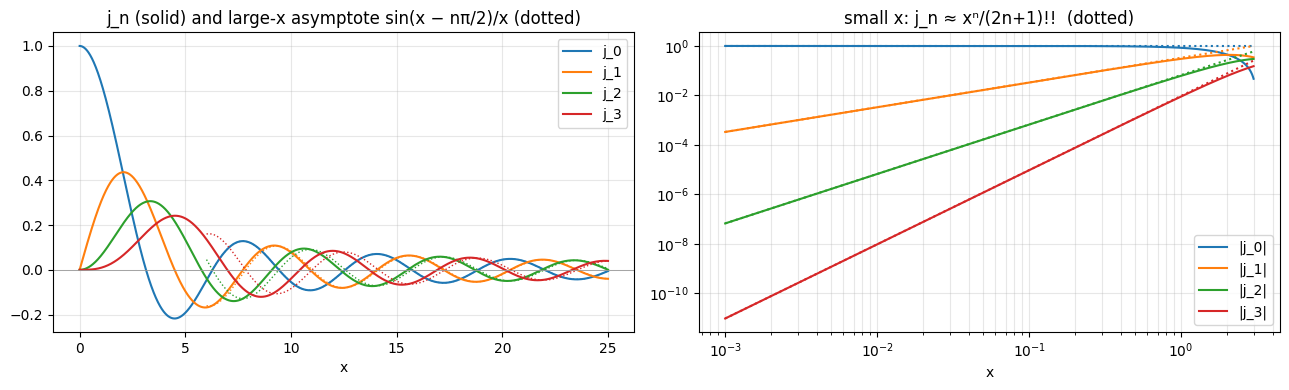

In [3]:
x = np.linspace(1e-3, 25, 1500)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for n, col in zip(range(4), ("C0", "C1", "C2", "C3")):
    axes[0].plot(x, spherical_jn(n, x), col, label=f"j_{n}")
    axes[0].plot(x[x > 6], np.sin(x[x > 6] - n*np.pi/2)/x[x > 6], col, ls=":", lw=1)
axes[0].axhline(0, color="0.6", lw=0.6)
axes[0].set(xlabel="x", title="j_n (solid) and large-x asymptote sin(x − nπ/2)/x (dotted)"); axes[0].legend(); axes[0].grid(alpha=0.3)
xx = np.linspace(1e-3, 3, 300)
for n, col in zip(range(4), ("C0", "C1", "C2", "C3")):
    lead = sp.lambdify(xs, small_x_leading(n), "numpy")
    axes[1].loglog(xx, np.abs(spherical_jn(n, xx)), col, label=f"|j_{n}|"); axes[1].loglog(xx, lead(xx) + 0*xx, col, ls=":")
axes[1].set(xlabel="x", title="small x: j_n ≈ xⁿ/(2n+1)!!  (dotted)"); axes[1].legend(); axes[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

**Gross behavior:** near the origin $j_n$ starts like $x^n$, so higher orders are pushed away
from the center (the "centrifugal barrier"). Far away, every $j_n$ is a sine wave fading like $1/x$:
an outgoing spherical wave whose *intensity* falls as $1/x^2$, the inverse-square law again.

# 2. From function to voltage

Map $x \in [0, 30]$ onto a 1 ms period and sample at 1 MS/s. A DAC then **offsets and scales**
$j_n \in [-0.22, 1]$ into $[0, 3.3]$ V, **rounds** to $N$ bits (quantization), and holds each
value for one sample (zero-order hold). The scope sees that through its own input bandwidth
(modeled as a first-order RC low-pass):

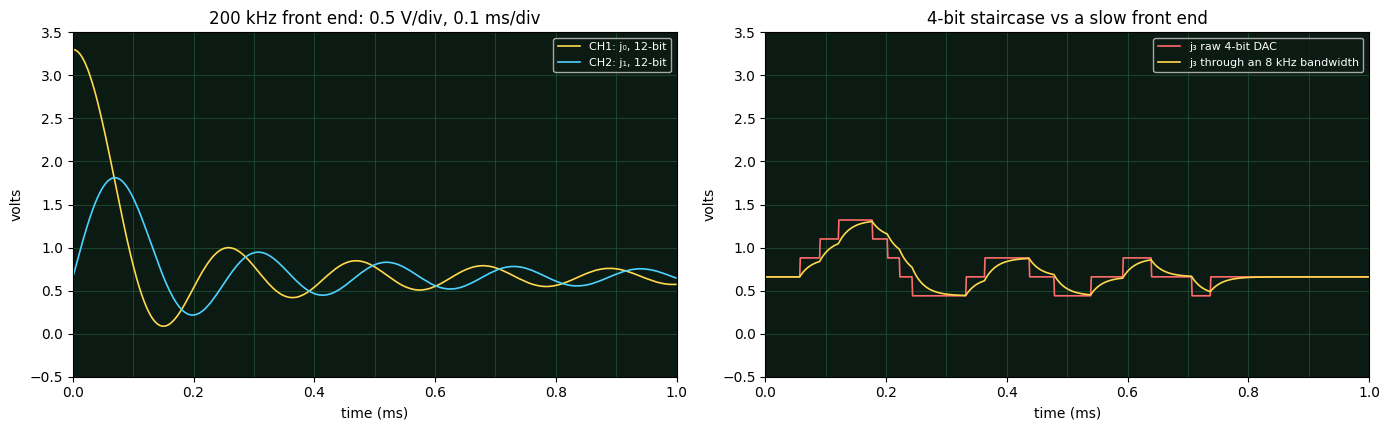

In [4]:
def scope_screen(ax, traces, t, v_div=0.5, t_div=1e-4, title=""):
    ax.set_facecolor("#0b1a12")
    for k in range(11): ax.axvline(k*t_div*1e3, color="#1f4d33", lw=0.6)
    for k in range(9): ax.axhline(k*v_div - 0.5, color="#1f4d33", lw=0.6)
    for (v, col, lab) in traces: ax.plot(t*1e3, v, color=col, lw=1.2, label=lab)
    ax.set(xlim=(0, 10*t_div*1e3), ylim=(-0.5, 8*v_div - 0.5), xlabel="time (ms)", ylabel="volts", title=title)
    ax.legend(fontsize=8, loc="upper right", facecolor="#0b1a12", labelcolor="w")
t, xg, y0 = waveform(0); _, _, y1 = waveform(1); _, _, y3 = waveform(3)
fs = 1e6
v0 = codes_to_volts(to_dac_codes(y0, 12)); v1 = codes_to_volts(to_dac_codes(y1, 12)); v3 = codes_to_volts(to_dac_codes(y3, 4), bits=4)   # bits must match the DAC, or the scale is off by 4095/15
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
scope_screen(axes[0], [(scope_view(v0, fs, 200e3), "#ffd84d", "CH1: j₀, 12-bit"), (scope_view(v1, fs, 200e3), "#4dd2ff", "CH2: j₁, 12-bit")],
             t, title="200 kHz front end: 0.5 V/div, 0.1 ms/div")
scope_screen(axes[1], [(v3, "#ff6b6b", "j₃ raw 4-bit DAC"), (scope_view(v3, fs, 8e3), "#ffd84d", "j₃ through an 8 kHz bandwidth")],
             t, title="4-bit staircase vs a slow front end")
plt.tight_layout(); plt.show()

,DAC bits,LSB (mV at 3.3 V),RMS error measured,LSB/√12 theory
0,4,220.000000,0.026353,0.024056
1,6,52.380952,0.005680,0.005728
2,8,12.941176,0.001431,0.001415
3,10,3.225806,0.000351,0.000353
4,12,0.805861,0.000088,0.000088
5,16,0.050355,0.000005,0.000006


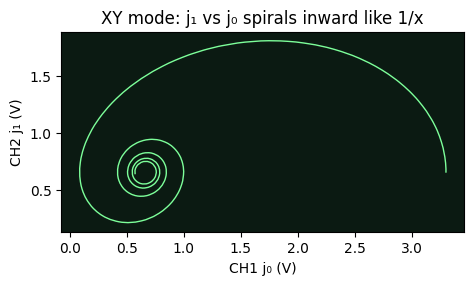

In [5]:
rows = []
for b in (4, 6, 8, 10, 12, 16):
    meas, theory = quantization_rms_error(waveform(2)[2], b)
    rows.append({"DAC bits": b, "LSB (mV at 3.3 V)": 3.3e3/(2**b - 1), "RMS error measured": meas, "LSB/√12 theory": theory})
display(pd.DataFrame(rows).round(6))
fig, ax = plt.subplots(figsize=(5.2, 5.2)); ax.set_facecolor("#0b1a12")
ax.plot(v0, v1, color="#7dff9a", lw=1); ax.set(xlabel="CH1 j₀ (V)", ylabel="CH2 j₁ (V)", title="XY mode: j₁ vs j₀ spirals inward like 1/x"); ax.set_aspect("equal"); plt.show()

In [ ]:
import sympy as sp
sp.init_printing()

Rin = 4e3
Rf = 12e3
vi = sp.symbols('v_i', real=True)

gain = -Rf/Rin
vo_ideal = gain*vi
gain, vo_ideal

Each extra DAC bit halves the step and the RMS error, about 6 dB per bit, and the measured
error matches $\text{LSB}/\sqrt{12}$, the uniform-quantization result. In **XY mode** the pair
$(j_0, j_1)$ traces a spiral that shrinks like $1/x$. That's the scope's way of showing the
asymptotic $\sin$/$\cos$ pair and its decaying amplitude.

# 3. Hardware: microcontroller lookup table, AWG file, USB budget

**Lookup table.** A microcontroller DAC (RP2040 + external DAC, ESP32, STM32, …) plays a waveform
by stepping through a table at a timer rate. `lut_header()` writes it as C. The test suite compiles
and runs it with gcc to prove it's valid C99:

In [6]:
hdr, codes = lut_header(0, size=256, bits=12)
(HW / "sph_j0_lut.h").write_text(hdr)
print(hdr[:520] + "  ...")
t_awg, _, y_awg = waveform(0, fs=1e6)
np.savetxt(HW / "j0_awg.csv", np.column_stack([t_awg, codes_to_volts(to_dac_codes(y_awg, 14), bits=14)]),
           delimiter=",", header="time_s,volts", comments="", fmt="%.9g")
print(f"\nwrote {HW/'sph_j0_lut.h'} and {HW/'j0_awg.csv'} ({len(t_awg)} points)")

/* j_0(x), x in [0, 30.0), 256 samples, 12-bit DAC codes.
   Generated by dgs/spherical_bessel_scope.py. code = round((j - (-0.25)) / 1.25 * 4095). */
#ifndef SPH_J0_LUT_H
#define SPH_J0_LUT_H
#include <stdint.h>
#define SPH_J0_LUT_SIZE 256
#define SPH_J0_LUT_BITS 12
static const uint16_t SPH_J0_LUT[256] = {
    4095, 4088, 4065, 4028, 3976, 3911, 3832, 3740, 3636, 3521, 3395, 3260,
    3117, 2967, 2811, 2650, 2486, 2320, 2152, 1985, 1820, 1657, 1498, 1344,
    1195, 1054,  921,  796,  680,  574,  479,  394,  320,   ...

wrote D:\Summer2026\Dispersion-Assisted-GS-Phase-Recovery\hardware\spherical_bessel\sph_j0_lut.h and D:\Summer2026\Dispersion-Assisted-GS-Phase-Recovery\hardware\spherical_bessel\j0_awg.csv (1000 points)


```c
// sketch of the playback loop (vendor DAC/timer APIs differ, so adapt to your board)
#include "sph_j0_lut.h"
volatile uint16_t i = 0;
void timer_isr(void) {               // fires at the sample rate, e.g. 256 kHz → 1 kHz waveform
    dac_write(SPH_J0_LUT[i]);         // board-specific: an MCP4725 over I2C, the ESP32 DAC, ...
    i = (i + 1) % SPH_J0_LUT_SIZE;
}
```

**AWG CSV.** Many arbitrary waveform generators import time/voltage CSV, but the exact
format is vendor-specific, so check your instrument's manual.

**USB budget.** USB-C is the *connector*. The data rate depends on the USB *version* behind it.
Most hobby microcontrollers run USB full-speed (12 Mbit/s raw, and well under that after protocol
overhead; here we assume 60%). That decides whether the PC can **stream** samples live, or whether
the board has to play from its own lookup table:

In [7]:
rows = []
for fs_, bits in ((1e6, 12), (500e3, 12), (100e3, 12), (1e6, 8), (100e3, 16)):
    b = usb_budget(fs_, bits)
    rows.append({"sample rate": f"{fs_/1e3:.0f} kS/s", "bits": bits, **{k: (round(v, 2) if isinstance(v, float) else v) for k, v in b.items()}})
pd.DataFrame(rows)

,sample rate,bits,needed Mbit/s,available Mbit/s,fits
0,1000 kS/s,12,16.0,7.2,False
1,500 kS/s,12,8.0,7.2,False
2,100 kS/s,12,1.6,7.2,True
3,1000 kS/s,8,8.0,7.2,False
4,100 kS/s,16,1.6,7.2,True


A 1 MS/s, 12-bit stream (sent as 2 bytes per sample) needs 16 Mbit/s, which doesn't fit
full-speed USB. Store the table **on the board** and send only commands over USB, or use a
high-speed (480 Mbit/s) USB device.

# 4. The quantum link: a spherical quantum dot

For a particle trapped in a sphere of radius $a$, the radial wavefunction is $j_l(kr)$ and must
vanish at the wall, so $k a = \beta_{n,l}$, the $n$-th zero of $j_l$. The energies are
$E_{n,l} = \hbar^2\beta_{n,l}^2/(2m a^2)$ [2]. The same zeros the scope trace crosses set the energy
levels. Here's a 2 nm dot (free-electron mass, an assumption; real semiconductors use an
effective mass):

,E (eV),n,l,β (zero of j_l)
0,0.0940,1,s,3.1416
1,0.1923,1,p,4.4934
2,0.3164,1,d,5.7635
3,0.3760,2,s,6.2832
4,0.5684,2,p,7.7253
5,0.7879,2,d,9.0950
6,0.8461,3,s,9.4248


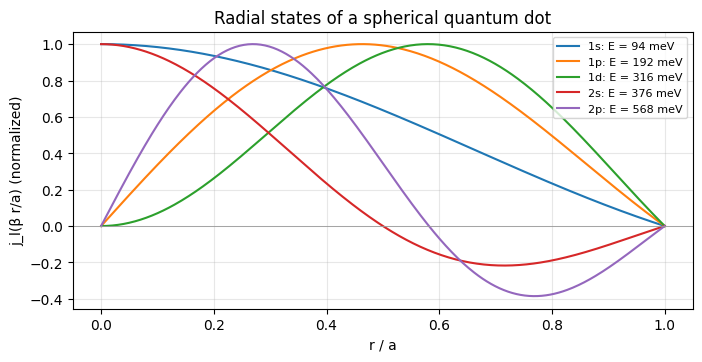

In [8]:
lv = spherical_box_levels(l_max=2, n_max=3, a_nm=2.0)
display(pd.DataFrame([{"E (eV)": e, "n": n, "l": "spd"[l], "β (zero of j_l)": b} for e, n, l, b in lv[:7]]).round(4))
r = np.linspace(0, 1, 400)
fig, ax = plt.subplots(figsize=(8, 3.6))
for e, n, l, b in lv[:5]:
    u = spherical_jn(l, b*r); ax.plot(r, u/np.max(np.abs(u)), label=f"{n}{'spd'[l]}: E = {e*1e3:.0f} meV")
ax.axhline(0, color="0.6", lw=0.6); ax.set(xlabel="r / a", ylabel="j_l(β r/a) (normalized)", title="Radial states of a spherical quantum dot")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()

Energies scale as $1/a^2$: shrink the dot and every level moves up. That's how quantum-dot
color is tuned by size, and why quantum dots are one of the solid-state platforms explored for
single-photon sources in quantum information science.

## Exercises
1. Play $j_2$ instead of $j_0$. Which part of the waveform suffers most from a 4-bit DAC, and why?
2. What scope bandwidth do you need so the j₀ trace error stays below 1 LSB at 12 bits?
3. With a USB high-speed link (480 Mbit/s, assume 60% usable), what is the fastest 16-bit stream?
4. Find the dot radius whose 1s→1p gap equals a 1550 nm photon (0.8 eV). Hint: the gap scales as $1/a^2$.